# 01 · STN vs. LSTN: scheduling a continuous industrial process

**Where this sits in the chain:** *process model* → parameter identification → dimension reduction → grid/aggregator optimization.

This notebook covers the first step for **continuous** processes (crushing, grinding, cement, steel powder):

1. Build a **State-Task Network (STN)** for a 10-stage steel powder plant and let it respond to an hourly electricity price.
2. Replace the STN's on/off binaries with **time-in-state** fractions to get the **LSTN**, which is a linear program.
3. Compare accuracy (cost, load profile) and **solve time as the number of factories grows**.

Every cell runs in seconds with the free HiGHS solver. The scaling demo (Section 4) takes about 1–2 minutes.

*References:* thesis Ch. 2; R. Lyu et al., "LSTN: A Linear Model of Industrial Production Process for Demand Response," ISGT Europe 2023. Plant data: R. Lu et al., *Appl. Energy* 283 (2021).

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ruikelyu/indflex/blob/main/notebooks/01_stn_vs_lstn.ipynb)

In [1]:
# On Google Colab, install indflex first (locally: pip install -e ".[dev]")
import sys
if "google.colab" in sys.modules:
    !pip install -q "indflex[dev] @ git+https://github.com/ruikelyu/indflex"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import indflex as fx
from indflex import viz

plt.rcParams["figure.dpi"] = 110

## 1. The plant: a serial production line

Each **stage** is a machine with a few **operating modes**. Mode $p$ of machine $n$ processes $g_{n,p}$ t/h and draws $e_{n,p}$ kW (mode 0 is *off*). Between consecutive stages sits a **buffer** (storage) with capacity $S^{\max}_n$. That buffer is what allows flexibility: upstream stages can run ahead while power is cheap, and downstream stages catch up later.

```
raw → [1 Atomizer] → S₁ → [2 Dehydrator] → S₂ → … → [10 Blender] → S₁₀ (final product)
```

The plant must deliver its daily output target $S^{\rm tar}$ by the end of the day.

In [3]:
plant = fx.load_plant("steel_powder_lu2021")
print(plant.description, "\nSource:", plant.source)
pd.DataFrame(
    [{"stage": f"{k+1}. {s.name}",
      "modes (g t/h, e kW)": ", ".join(f"({m.g:g}, {m.e:g})" for m in s.modes),
      "buffer max (t)": s.s_max, "initial (t)": s.s_init, "daily target (t)": s.s_target_change}
     for k, s in enumerate(plant.stages)]
)

Steel powder manufacturing, 10 serial stages. Used by stn_demo.m. Separator rate g = 10 t/h. 
Source: R. Lu et al., 'Data-driven real-time price-based demand response for industrial facilities energy management', Appl. Energy 283 (2021) 116291.


,stage,"modes (g t/h, e kW)",buffer max (t),initial (t),daily target (t)
0,1. Atomizer,"(0, 0), (30, 60)",180.0,90.0,0.0
1,2. Dehydrator,"(0, 0), (15, 10)",100.0,50.0,0.0
2,3. Dryer,"(0, 0), (15, 30)",150.0,75.0,0.0
3,4. Crusher,"(0, 0), (10, 15), (15, 20)",100.0,50.0,0.0
4,5. Classifier,"(0, 0), (10, 15), (20, 25)",150.0,75.0,0.0
5,6. Separator,"(0, 0), (10, 10)",100.0,50.0,0.0
6,7. Reduction,"(0, 0), (15, 75)",100.0,50.0,0.0
7,8. Crusher,"(0, 0), (10, 15), (15, 20)",100.0,50.0,0.0
8,9. Classifier,"(0, 0), (10, 15), (20, 25)",150.0,75.0,0.0
9,10. Blender,"(0, 0), (10, 6), (15, 10)",400.0,0.0,240.0


## 2. STN: on/off scheduling (a MILP)

Decision variable $x_{n,p,t}\in\{0,1\}$: machine $n$ runs in mode $p$ during hour $t$.

$$
\begin{aligned}
\min\ & \textstyle\sum_t \pi_t \sum_n E_{n,t}, \qquad E_{n,t}=\sum_p e_{n,p}\,x_{n,p,t}\,\Delta t \\
\text{s.t. }& \textstyle\sum_p x_{n,p,t}=1 &&\text{one mode at a time}\\
& S_{n,t+1}=S_{n,t}+G_{n,t}-G_{n+1,t},\quad G_{n,t}=\sum_p g_{n,p}\,x_{n,p,t}\,\Delta t &&\text{buffer balance}\\
& 0\le S_{n,t}\le S^{\max}_n,\qquad S_{n,T}\ge S_{n,0}+S^{\rm tar}_n &&\text{capacity and target}
\end{aligned}
$$

Use the sliders to change the day (PJM real-time prices, July 2022) and the daily production target. Watch the plant move its load into cheap hours.

In [4]:
from ipywidgets import interact, IntSlider

prices = fx.load_prices("2022-07")

@interact(day=IntSlider(23, 1, 31, description="July day"),
          target=IntSlider(240, 120, 300, step=20, description="target (t)"))
def show_stn(day, target):
    price = prices.iloc[day - 1].to_numpy()
    r = fx.solve(fx.build_stn(plant.with_target(target), price))
    if r.status != "optimal":
        print("No feasible schedule:", r.status)
        return
    viz.plot_schedule(r, price, title=f"STN, July {day}: cost ${r.cost:,.2f}, {r.n_binary} binaries, {r.solve_seconds:.2f} s")
    plt.show()

interactive(children=(IntSlider(value=23, description='July day', max=31, min=1), IntSlider(value=240, descrip…

## 3. LSTN: model *how long* each machine runs in each mode

Market intervals (1 h) are much longer than the time a machine needs to switch modes. So instead of asking *which* mode the machine is in for the whole hour, the LSTN asks *how long* it spends in each mode:

$$x_{n,p,t}\in[0,1]\quad\text{(fraction of hour } t \text{ spent in mode } p\text{)},\qquad \textstyle\sum_p x_{n,p,t}=1.$$

All other constraints are unchanged. The model becomes a **linear program**. In code, the only difference is `relax=True`:

STN : optimal: cost $256.91, total 3,954.0 kWh, 600 binary / 250 continuous vars, 0.10 s
LSTN: optimal: cost $256.26, total 3,954.0 kWh, 0 binary / 850 continuous vars, 0.06 s
Cost gap: 0.26%  (the LSTN is a lower bound on the STN)


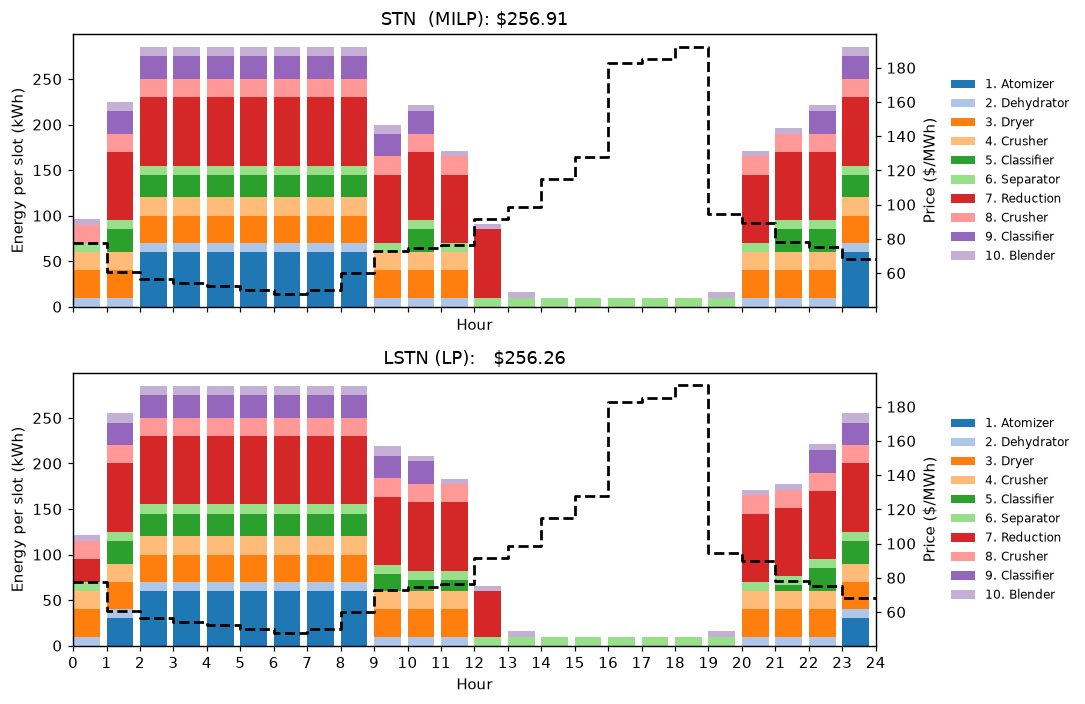

In [5]:
day = 23
price = prices.iloc[day - 1].to_numpy()
stn = fx.solve(fx.build_stn(plant, price))
lstn = fx.solve(fx.build_lstn(plant, price))
print("STN :", stn.summary())
print("LSTN:", lstn.summary())
print(f"Cost gap: {(stn.cost - lstn.cost) / stn.cost:.2%}  (the LSTN is a lower bound on the STN)")

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
viz.plot_schedule(stn, price, title=f"STN  (MILP): ${stn.cost:,.2f}", ax=axes[0])
viz.plot_schedule(lstn, price, title=f"LSTN (LP):   ${lstn.cost:,.2f}", ax=axes[1])
plt.tight_layout(); plt.show()

**How close is it on every day?** Solve both models for all 31 days of July (about 5 s):

,STN cost,LSTN cost,cost gap %,load profile diff %
mean,264.238,263.143,0.422,4.083
max,375.509,374.781,0.998,8.489


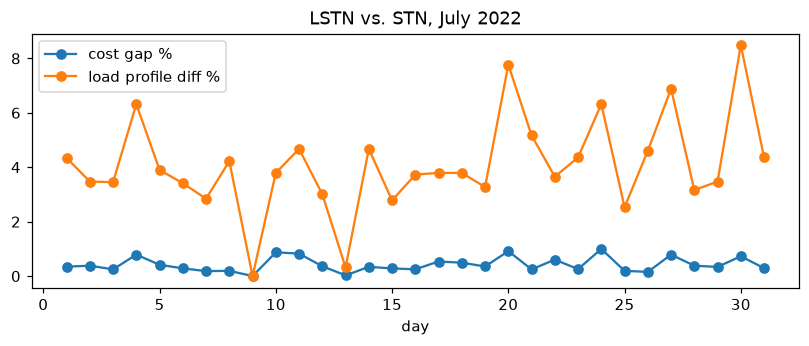

In [6]:
rows = []
for d in range(1, 32):
    p = prices.iloc[d - 1].to_numpy()
    a, b = fx.solve(fx.build_stn(plant, p)), fx.solve(fx.build_lstn(plant, p))
    rows.append({"day": d, "STN cost": a.cost, "LSTN cost": b.cost,
                 "cost gap %": 100 * (a.cost - b.cost) / a.cost,
                 "load profile diff %": 100 * np.abs(a.load - b.load).sum() / a.load.sum()})
gap = pd.DataFrame(rows).set_index("day")
display(gap.describe().loc[["mean", "max"]].round(3))
gap[["cost gap %", "load profile diff %"]].plot(marker="o", figsize=(9, 3), title="LSTN vs. STN, July 2022"); plt.show()

## 4. Scaling: many factories at once

An aggregator or a grid model needs **many** factories at once. Here we schedule fleets of randomized steel-powder factories (parameters scaled by random factors in [0.8, 1.2], as in the LSTN paper) against one price.

* **STN**: binaries grow with the fleet, and HiGHS soon hits the time limit.
* **LSTN**: an LP that stays fast for hundreds of factories.

The sizes below are chosen so that the whole cell finishes in about 1–2 minutes: the STN reaches the time limit at around 5 factories, while the LSTN solves 200 in about 10 s. Change `TIME_LIMIT` or the size lists to explore. With a commercial solver (Gurobi or CPLEX), the paper solves 2,000 LSTN factories in minutes, while the STN fails to converge within 2 h for 20 factories.

STN  n=   1: optimal      10.0 s, 720 binaries


STN  n=   2: optimal       7.7 s, 1440 binaries


STN  n=   3: time limit   30.4 s, 2160 binaries


STN  n=   5: time limit   30.6 s, 3600 binaries


LSTN n=   1: optimal       0.2 s, 0 binaries


LSTN n=   2: optimal       0.4 s, 0 binaries


... (2 outputs left out)

LSTN n=  20: optimal       5.1 s, 0 binaries


LSTN n=  50: optimal       8.0 s, 0 binaries


LSTN n= 100: optimal      15.1 s, 0 binaries


LSTN n= 200: optimal      18.5 s, 0 binaries


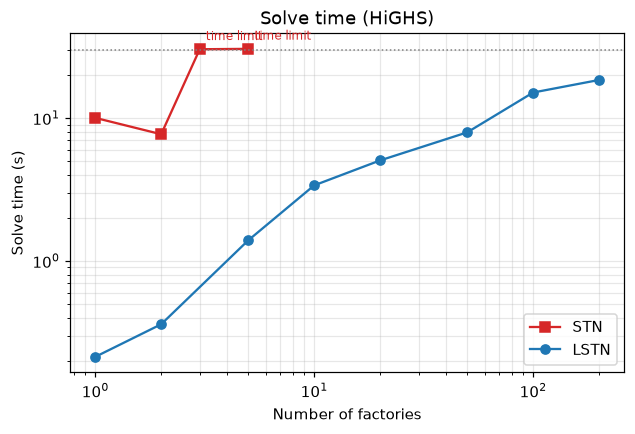

In [7]:
TIME_LIMIT = 30                       # seconds per solve
STN_SIZES = [1, 2, 3, 5]
LSTN_SIZES = [1, 2, 5, 10, 20, 50, 100, 200]

fleet = fx.load_fleet(200)            # take the first n factories of one 200-factory fleet
price_aug5 = fx.daily_price("2022-08", 5)
rows = []
for model, sizes, relax in [("STN", STN_SIZES, False), ("LSTN", LSTN_SIZES, True)]:
    for n in sizes:
        r = fx.solve(fx.build_fleet(fleet[:n], price_aug5, relax=relax), time_limit=TIME_LIMIT)
        rows.append({"model": model, "n": n, "seconds": r.solve_seconds, "status": r.status,
                     "binaries": r.n_binary, "cost": r.cost})
        print(f"{model:4s} n={n:4d}: {r.status:10s} {r.solve_seconds:6.1f} s, {r.n_binary} binaries")

scaling = pd.DataFrame(rows)
viz.plot_scaling(rows, time_limit=TIME_LIMIT); plt.title("Solve time (HiGHS)"); plt.show()

## 5. Things to try

1. Shrink a buffer: `fx.load_plant(...)` returns a frozen dataclass; build a modified copy with `dataclasses.replace` and see how much flexibility disappears.
2. Raise the target to 300 t in Section 2. When does the plant lose its ability to avoid the evening peak?
3. Use 15-minute intervals: `fx.build_lstn(plant, np.repeat(price, 4), dt=0.25)`.

**Takeaways**
* For continuous processes, the LSTN keeps the STN's material-flow logic but drops the binaries, so it scales to fleets.
* Its cost is a lower bound on the STN's. For this plant it is within about 1% on every day of July 2022 (0.4% on average), and the hourly load profiles differ by about 4% on average.
* Batch processes (e.g. steelmaking heats that cannot be interrupted) need more structure → **notebook 02: RTN vs. cRTN**